In [2]:
#setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shapefile
import pydeck as pdk
import re
from matplotlib.path import Path
from matplotlib.patches import PathPatch

RAW = "data/raw/"
CLEAN = "data/clean/"
FIGURES = "figures/"

In [3]:
#Formatting for charts
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelcolor": "#555555",
    "xtick.color": "#555555",
    "ytick.color": "#555555",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#BBBBBB",
    "axes.grid": True,
    "grid.color": "#EEEEEE",
    "axes.axisbelow": True,
    "figure.figsize": (7, 4.5),
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834"]),
})

## 1. Get lung cancer incidence, 2019–2023
Age-adjusted new cases per 100,000 people, by county (State Cancer Profiles). Counties with too few cases have their rates suppressed, so they appear as missing.

In [4]:
# Load the table
cancer = pd.read_csv(RAW + "incd.csv", 
         skiprows=8, nrows=3145, # 8 title lines sit above the header, and notes follow the data, so remove them.
         dtype={"FIPS": str}, # Read FIPS as text so codes like "01001" keep their leading zero
         na_values=["*", "* ", " *"]) # Cells with no data contain "*" (sometimes with a space), so have pandas read those as blank.

# Keep the first six columns. The other columns are unnecessary
cancer = cancer.iloc[:, :6]
cancer.columns = ["name", "fips", "rural_urban", "cancer_rate", "rate_lower", "rate_upper"]

# Bedford County, VA is blank; its combined city/county row says Urban
cancer.loc[cancer["fips"] == "51019", "rural_urban"] = "Urban"

# Drop rows that aren't counties: U.S. total, Puerto Rico, Bedford combined row
cancer = cancer[~cancer["fips"].isin(["00000", "72001", "51917"])].copy()

# Remove footnote marks like "(2)"
cancer["name"] = cancer["name"].str.replace(r"\(.*\)", "", regex=True)

cancer.to_csv(CLEAN + "cancer.csv", index=False)
print(len(cancer), "counties,", cancer["cancer_rate"].isna().sum(), "with no rate")
cancer.head()

3142 counties, 277 with no rate


,name,fips,rural_urban,cancer_rate,rate_lower,rate_upper
1,"Union County, Florida",12125,Rural,147.1,124.3,173.1
2,"McCreary County, Kentucky",21147,Rural,134.5,113.3,158.9
3,"Owsley County, Kentucky",21189,Rural,132.8,92.8,186.0
4,"Lincoln County, West Virginia",54043,Rural,130.3,112.8,150.1
5,"Powell County, Kentucky",21197,Rural,129.3,105.5,157.4


## 2. Get air pollution concentration (PM2.5), 1999–2003
Modeled annual fine-particle pollution (µg/m³), by county (CACES), averaged over the five years that fall 20 years before the cancer data. Covers the lower 48 states and DC.

In [5]:
# Read FIPS as text so codes like "01001" keep their leading zero
pollution = pd.read_csv(RAW + "CACE_data.csv", dtype={"fips": str})

# Keep only data columns for 1999–2003
pollution = pollution[pollution["year"].between(1999, 2003)]

# Oglala Lakota County, SD changed its FIPS code; use the one in the cancer data
pollution["fips"] = pollution["fips"].replace("46113", "46102")

# Average each county's five years into one number
pollution = pollution.groupby("fips", as_index=False)["pred_wght"].mean()
pollution.columns = ["fips", "pm25"]

pollution.to_csv(CLEAN + "pollution.csv", index=False)
print(len(pollution), "counties")
pollution["pm25"].describe()

3109 counties


count    3109.000000
mean       10.761018
std         2.836477
min         3.552076
25%         8.438876
50%        11.192136
75%        13.054990
max        20.087391
Name: pm25, dtype: float64

## 3. Get smoking rates, 1999–2003
Modeled percentage of all adults who smoke, by county, both sexes (IHME), averaged over the same five years as pollution. A few counties share one estimate because IHME merged them.

In [6]:
# Load the data
folder = "IHME_US_COUNTY_TOTAL_AND_DAILY_SMOKING_PREVALENCE_1996_2012/"
smoking = pd.read_csv(RAW + folder + "IHME_US_COUNTY_TOTAL_AND_DAILY_SMOKING_PREVALENCE_1996_2012.csv")

# Keep both sexes and 1999–2003 data; drop all rows with no county as they are state or national totals
smoking = smoking[(smoking["sex"] == "Both") & smoking["year"].between(1999, 2003)]
smoking = smoking.dropna(subset=["county"])

# Average each county's five years of total smoking (each county/year is a separate row, so 5 in total)
smoking = smoking.groupby(["state", "county"], as_index=False)["total_mean"].mean()
smoking.columns = ["state", "county", "smoking"]
smoking["smoking"] = smoking["smoking"].round(1) # Keep it to one decimal

# Merged areas look like "Fairfax County/Fairfax City": give each county its own row
smoking["county"] = smoking["county"].str.split("/")
smoking = smoking.explode("county")

# Build names that match the cancer data, then fix the ones spelled differently
smoking["name"] = smoking["county"] + ", " + smoking["state"]
fixes = {
    "LaSalle County, Illinois": "La Salle County, Illinois",
    "Lafourche Parish, Louisiana": "LaFourche Parish, Louisiana",
    "Prince George's County, Maryland": "Prince Georges County, Maryland",
    "Queen Anne's County, Maryland": "Queen Annes County, Maryland",
    "St. Mary's County, Maryland": "St. Marys County, Maryland",
    "De Baca County, New Mexico": "DeBaca County, New Mexico",
    "Shannon County, South Dakota": "Oglala Lakota, South Dakota",
    "Alleghany County, Virginia": "Alleghany County and Clifton Forge City, Virginia",
    "Halifax County, Virginia": "Halifax County with South Boston City, Virginia",
    "District of Columbia, District Of Columbia": "District of Columbia",
}
smoking["name"] = smoking["name"].replace(fixes) 
smoking = smoking[["name", "smoking"]] # keeps only the 2 columns I need

smoking.to_csv(CLEAN + "smoking.csv", index=False)
print(len(smoking), "counties")
smoking["smoking"].describe()

3143 counties


count    3143.000000
mean       26.869838
std         3.666148
min        10.400000
25%        24.450000
50%        27.000000
75%        29.300000
max        42.100000
Name: smoking, dtype: float64

## 4. Merge all the data into one table
Joins cancer, pollution and smoking, keeping only counties found in all three. Alaska and Hawaii drop out because the pollution data doesn't cover them.

In [7]:
# Join on FIPS where we have it, and on county name for smoking
counties = cancer.merge(pollution, on="fips").merge(smoking, on="name")

counties.to_csv(CLEAN + "counties.csv", index=False)
print(len(counties), "counties,", counties["cancer_rate"].notna().sum(), "with a cancer rate")
counties.head()

3108 counties, 2845 with a cancer rate


,name,fips,rural_urban,cancer_rate,rate_lower,rate_upper,pm25,smoking
0,"Union County, Florida",12125,Rural,147.1,124.3,173.1,10.748303,30.4
1,"McCreary County, Kentucky",21147,Rural,134.5,113.3,158.9,12.955548,37.2
2,"Owsley County, Kentucky",21189,Rural,132.8,92.8,186.0,12.433739,37.3
3,"Lincoln County, West Virginia",54043,Rural,130.3,112.8,150.1,14.122201,34.5
4,"Powell County, Kentucky",21197,Rural,129.3,105.5,157.4,13.350826,37.2


## 5. Analyze the connection between pollution and lung cancer
Do counties with more PM2.5 in 1999–2003 have higher lung cancer rates in 2019–2023? Each dot is one county.

Correlation: 0.43


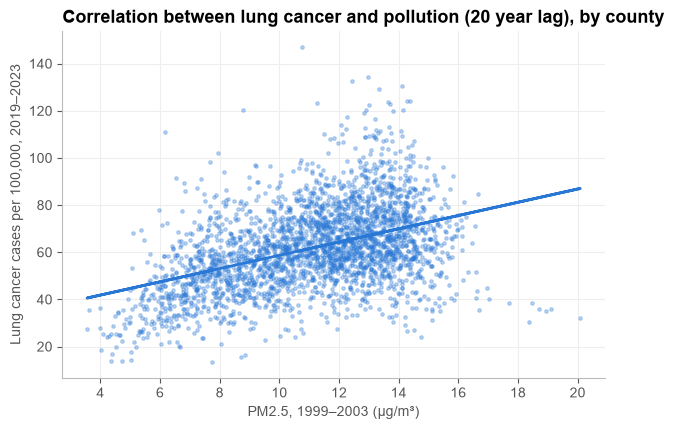

In [18]:
# Correlation runs from -1 to 1; 0 means no straight-line relationship
r = counties["pm25"].corr(counties["cancer_rate"])
print("Correlation:", round(r, 2))

# s is the dot size; alpha makes dots see-through so crowded areas show up
ax = counties.plot.scatter(x="pm25", y="cancer_rate", s=6, alpha=0.3,
                           xlabel="PM2.5, 1999–2003 (µg/m³)",
                           ylabel="Lung cancer cases per 100,000, 2019–2023",
                           title="Correlation between lung cancer and pollution (20 year lag), by county")

# Sets the range and decimal places for tick marks
ax.set_xticks(range(4, 22, 2))

# Find the best-fit straight line, using only counties with a cancer rate
has_rate = counties.dropna(subset=["cancer_rate"])
slope, intercept = np.polyfit(has_rate["pm25"], has_rate["cancer_rate"], 1)

# Draw the line; C0 is the same blue as the dots
ax.plot(has_rate["pm25"], slope * has_rate["pm25"] + intercept, color="C0", linewidth=2);

# Save the figure
plt.savefig(FIGURES + "Scatterplot_pollution_vs_cancer.png", dpi=200, bbox_inches="tight")
plt.savefig("scrolly-test/Scatterplot_pollution_vs_cancer.png", dpi=200, bbox_inches="tight")

Another way of looking at the correlation would be to ompare average cancer rates across four equal groups of counties, from least to most polluted:”

In [9]:
print("Share of differences explained:", round(r**2, 2))
print("Extra cases per 100,000 for each extra 1 µg/m³:", round(slope, 1))

# Average cancer rate for four equal-sized groups, from least to most polluted
groups = pd.qcut(has_rate["pm25"], 4, labels=["Lowest", "Second", "Third", "Highest"])
has_rate.groupby(groups, observed=True)[["pm25", "cancer_rate"]].mean().round(1)

Share of differences explained: 0.18
Extra cases per 100,000 for each extra 1 µg/m³: 2.8


,pm25,cancer_rate
pm25,,
Lowest,7.4,49.6
Second,10.4,62.1
Third,12.4,66.9
Highest,14.2,68.6


Each additional 1 µg/m³ of PM2.5 in the years around 2000 is associated with about 2.8 more lung cancer cases per 100,000 people today. Counties in the most polluted quarter have rates about 38% higher than those in the least polluted quarter (68.6 vs. 49.6). 

## 6. Prepare map showing where pollution and lung cancer overlap
The scatterplot above shows how strongly pollution and lung cancer move together on average, but it doesn't show **where** in the country the connection is highest. The map below places each county in one of three equal groups for PM2.5 (1999–2003) and one of three for lung cancer (2019–2023), then combines them into nine colors.

**How to read it:** 
Dark red counties are high on both, and pale counties are low on both. Yellow counties had high pollution but have low cancer rates, and blue counties had low pollution but have high cancer rates. Gray counties have too few cases to report a rate.

If pollution and cancer were unrelated, each of the nine combinations would hold about 316 counties. Instead, 562 are low on both and 453 are high on both, while only 182 and 129 fall in the opposite corners.

This map shows the raw pattern and doesn't account for other factors.

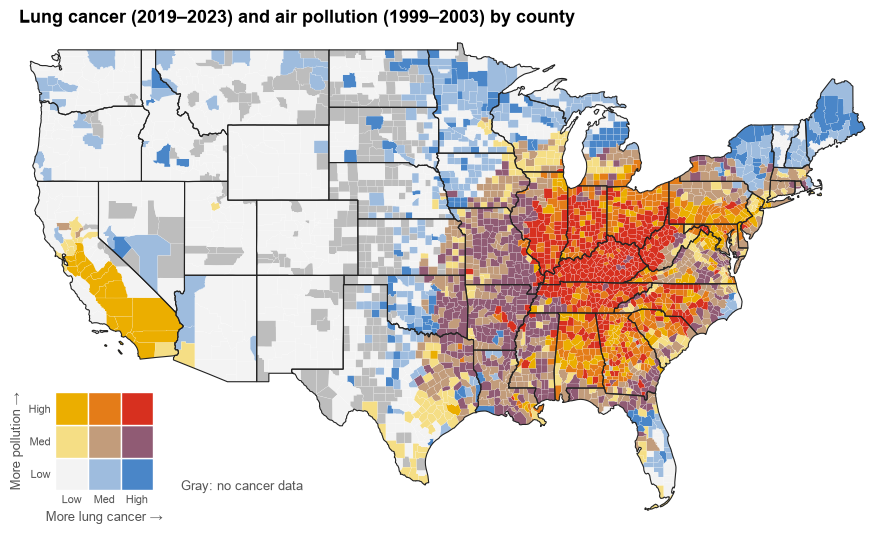

In [10]:
# Put counties into three equal groups on each measure (0 = low, 1=medium, 2 = high)
pollution_level = pd.qcut(has_rate["pm25"], 3, labels=False)
cancer_level = pd.qcut(has_rate["cancer_rate"], 3, labels=False)

# Rows are pollution (low to high); columns are cancer (low to high)
colors = [["#F3F3F3", "#9EBCDE", "#4A86C8"],
          ["#F5DE85", "#C29C7B", "#905B74"],
          ["#EBAE00", "#E47C18", "#D7301F"]]
county_color = {fips: colors[p][c] for fips, p, c in zip(has_rate["fips"], pollution_level, cancer_level)}

# Turn a shape from the shapefile into an outline (handles islands and holes)
def outline(shape):
    starts = list(shape.parts) + [len(shape.points)]
    return Path.make_compound_path(*[Path(shape.points[a:b]) for a, b in zip(starts, starts[1:])])

fig, ax = plt.subplots(figsize=(11, 7))
skip = ["02", "15", "72"]  # Alaska, Hawaii, Puerto Rico

# Draw counties, then state borders on top
for item in shapefile.Reader(RAW + "cb_2020_us_county_20m/cb_2020_us_county_20m.shp").shapeRecords():
    if item.record["STATEFP"] not in skip:
        color = county_color.get(item.record["GEOID"], "#BDBDBD")
        ax.add_patch(PathPatch(outline(item.shape), facecolor=color, edgecolor="white", linewidth=0.1))

for item in shapefile.Reader(RAW + "cb_2020_us_state_20m/cb_2020_us_state_20m.shp").shapeRecords():
    if item.record["STATEFP"] not in skip:
        ax.add_patch(PathPatch(outline(item.shape), facecolor="none", edgecolor="#222222", linewidth=0.8))

# Frame the lower 48 and hide the axes
ax.set_xlim(-125.5, -66.5)
ax.set_ylim(24, 50)
ax.set_aspect(1.3)
ax.axis("off")

# Draw the 3x3 legend in the corner
key = ax.inset_axes([0.03, 0.06, 0.14, 0.2])
for p in range(3):
    for c in range(3):
        key.add_patch(plt.Rectangle((c, p), 1, 1, facecolor=colors[p][c], edgecolor="white"))
key.set_xlim(0, 3)
key.set_ylim(0, 3)
key.set_aspect("equal")
key.set_xticks([0.5, 1.5, 2.5], ["Low", "Med", "High"], fontsize=8)
key.set_yticks([0.5, 1.5, 2.5], ["Low", "Med", "High"], fontsize=8)
key.tick_params(length=0)
key.grid(False)
key.spines[:].set_visible(False)
key.set_xlabel("More lung cancer →", fontsize=9)
key.set_ylabel("More pollution →", fontsize=9)
ax.text(0.19, 0.06, "Gray: no cancer data", transform=ax.transAxes, fontsize=9, color="#555555")

ax.set_title("Lung cancer (2019–2023) and air pollution (1999–2003) by county")
plt.savefig(FIGURES + "Choropleth_map_pollution_vs_cancer.png")

## 6 (Continued) - try a different type of map

In [11]:
# Preparing a new map based on Pydeck (like https://deckgl.readthedocs.io/en/latest/gallery/geojson_layer.html)
# Each county's height is the difference between the county's cancer rate ABOVE the national average of 51.8 per 100,000 people.
# Countries BELOW the national average stay flat.

# National rate for 2019–2023, from the U.S. row in incd.csv
national_rate = 51.8

# Five shades of amber, from least to most polluted
grays = [[250, 238, 194], [243, 211, 107], [235, 174, 0], [185, 127, 0], [122, 82, 0]]

# Add each county's shade and bar height; counties below the national rate stay flat
map_data = has_rate.copy()
map_data["shade"] = pd.qcut(map_data["pm25"], 5, labels=False)
map_data["height"] = (map_data["cancer_rate"] - national_rate).clip(lower=0)
lookup = map_data.set_index("fips").to_dict("index")

# Build one map feature per county, with the values the map needs attached
features = []
for item in shapefile.Reader(RAW + "cb_2020_us_county_20m/cb_2020_us_county_20m.shp").shapeRecords():
    if item.record["STATEFP"] not in skip:
        feature = item.__geo_interface__
        county = lookup.get(item.record["GEOID"])
        if county:
            feature["properties"] = {"name": county["name"], "cancer_rate": county["cancer_rate"], "pm25": county["pm25"],
                                     "smoking": county["smoking"], "height": county["height"], "color": grays[county["shade"]]}
        else:
            feature["properties"] = {"name": item.record["NAME"], "cancer_rate": "no data", "pm25": "no data",
                                     "smoking": "no data", "height": 0, "color": [189, 189, 189]}
        features.append(feature)

# The county layer: color comes from "color", height from "height"
layer = pdk.Layer("GeoJsonLayer", {"type": "FeatureCollection", "features": features},
                  filled=True, stroked=True, extruded=True, pickable=True,
                  get_fill_color="properties.color", get_elevation="properties.height",
                  elevation_scale=4000, get_line_color=[255, 255, 255])

# Black state outlines, drawn on top of the raised counties
states = []
for item in shapefile.Reader(RAW + "cb_2020_us_state_20m/cb_2020_us_state_20m.shp").shapeRecords():
    if item.record["STATEFP"] not in skip:
        feature = item.__geo_interface__
        feature["properties"] = {}
        states.append(feature)

state_layer = pdk.Layer("GeoJsonLayer", {"type": "FeatureCollection", "features": states},
                        filled=False, stroked=True, get_line_color=[0, 0, 0], line_width_min_pixels=1,
                        parameters={"depthCompare": "always"})

# Starting camera: centered on the lower 48, tilted to show height
view = pdk.ViewState(latitude=36, longitude=-96, zoom=3.7, pitch=50, bearing=-10)

# What appears when a reader hovers over a county
tooltip = {"html": "<b>{name}</b><br>Lung cancer: {cancer_rate} per 100,000<br>PM2.5: {pm25} µg/m³<br>Adults who smoked: {smoking}%"}

deck = pdk.Deck(layers=[layer, state_layer], initial_view_state=view, map_style=None, tooltip=tooltip)
deck.to_html(FIGURES + "3D_map_pollution_cancer.html", open_browser=False)

# Title and legend, placed in the top-left corner of the page
overlay = """
<div style="position: absolute; top: 16px; left: 16px; z-index: 10; width: 330px; max-width: 80%; padding: 14px 16px;
            background: rgba(255, 255, 255, 0.92); font-family: Arial, sans-serif; color: #333; pointer-events: none;">
  <div style="font-size: 20px; font-weight: bold; line-height: 1.2;">Lung cancer and past air pollution, by county</div>
  <div style="font-size: 12px; color: #666; margin: 4px 0 12px;">Hover over a county for details. Drag to move, or hold Shift and drag to rotate.</div>

  <div style="font-size: 12px; font-weight: bold; margin-bottom: 4px;">Color: air pollution (PM2.5, µg/m³), 1999–2003</div>
  <div style="display: flex; height: 12px;">
    <div style="flex: 1; background: #FAEEC2;"></div>
    <div style="flex: 1; background: #F3D36B;"></div>
    <div style="flex: 1; background: #EBAE00;"></div>
    <div style="flex: 1; background: #B97F00;"></div>
    <div style="flex: 1; background: #7A5200;"></div>
  </div>
  <div style="display: flex; font-size: 10px; color: #555; text-align: center; margin-top: 3px;">
    <div style="flex: 1;">3.6–8.6</div>
    <div style="flex: 1;">8.6–10.7</div>
    <div style="flex: 1;">10.7–12.2</div>
    <div style="flex: 1;">12.2–13.5</div>
    <div style="flex: 1;">13.5–20.1</div>
  </div>

  <div style="font-size: 12px; font-weight: bold; margin: 12px 0 2px;">Height: lung cancer, 2019–2023</div>
  <div style="font-size: 11px; color: #555; line-height: 1.35;">Taller counties are further above the U.S. rate of 51.8 cases per 100,000. Flat counties are at or below it.</div>

  <div style="display: flex; align-items: center; font-size: 11px; color: #555; margin-top: 10px;">
    <div style="width: 12px; height: 12px; background: #BDBDBD; margin-right: 6px;"></div>No cancer data
  </div>
</div>
"""

# Open the saved map, shrink it, add the overlay, and save it again
file = open(FIGURES + "3D_map_pollution_cancer.html", encoding="utf-8")
html = file.read()
file.close()

html = re.sub(r"\s*\n\s*(-?\d|\[|\])", r"\1", html)
html = re.sub(r"(\.\d{3})\d+", r"\1", html)

file = open(FIGURES + "3D_map_pollution_cancer.html", "w", encoding="utf-8")
file.write(html.replace("</body>", overlay + "</body>"))
file.close()

## 7. Consider smoking as a factor in cancer rates; analyze the connection between smoking and lung cancer
The choropleth above shows the correlation between pollution and cancer. But pollution alone accounts for only about 18% of the differences between counties. What else might account for these differences across counties? I'm guessing that smoking rates in different counties has a lot to do with it...

Smoking is the leading cause of lung cancer, so counties with more smokers should have higher rates. If those same counties also had more pollution, the pollution pattern above could be partly a smoking pattern. The following scatterplot reveals just how strongly correlated smoking is with cancer.

Smoking and cancer: 0.74
Pollution and smoking: 0.36


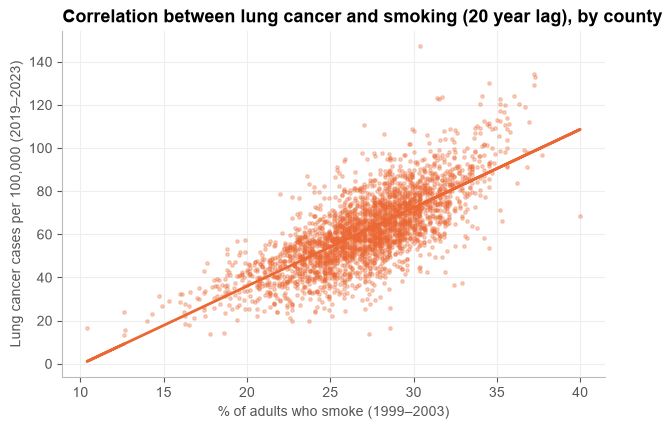

In [12]:
# How closely does smoking track cancer, and does smoking overlap with pollution?
smoke_r = has_rate["smoking"].corr(has_rate["cancer_rate"])
print("Smoking and cancer:", round(smoke_r, 2))
print("Pollution and smoking:", round(has_rate["pm25"].corr(has_rate["smoking"]), 2))

# Same chart as before, with smoking in orange (C1)
ax = has_rate.plot.scatter(x="smoking", y="cancer_rate", s=6, alpha=0.3, color="C1",
                           xlabel="% of adults who smoke (1999–2003)",
                           ylabel="Lung cancer cases per 100,000 (2019–2023)",
                           title="Correlation between lung cancer and smoking (20 year lag), by county")

# Add the best-fit line
smoke_slope, smoke_intercept = np.polyfit(has_rate["smoking"], has_rate["cancer_rate"], 1)
ax.plot(has_rate["smoking"], smoke_slope * has_rate["smoking"] + smoke_intercept, color="C1", linewidth=2);

# Save the figure
plt.savefig(FIGURES + "Scatterplot_smoking_vs_cancer.png")

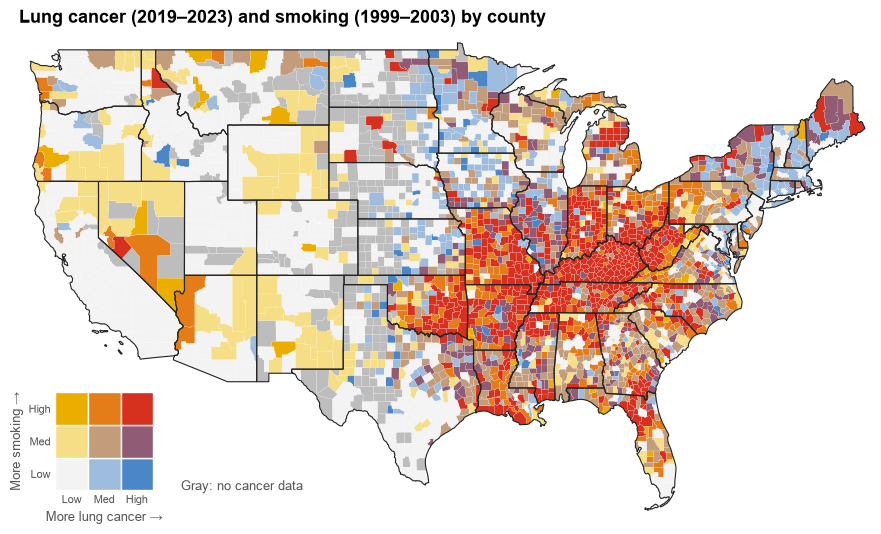

In [13]:
#  Put counties into three equal groups on each measure (0 = low, 1 = medium, 2 = high)
smoking_level = pd.qcut(has_rate["smoking"], 3, labels=False) # cuts counties into 3 groups by smoking rates (lo, med, hi)
cancer_level = pd.qcut(has_rate["cancer_rate"], 3, labels=False) # does the same thing for cancer rates (same as map above)

# Same colors as the pollution map, but rows are now for smoking (low to high)
# *s* is for the row and *c* is for position (column)
county_color = {fips: colors[s][c] for fips, s, c in zip(has_rate["fips"], smoking_level, cancer_level)} # picks up same scheme as for pollution.

fig, ax = plt.subplots(figsize=(11, 7))

# Draw counties
for item in shapefile.Reader(RAW + "cb_2020_us_county_20m/cb_2020_us_county_20m.shp").shapeRecords():
    if item.record["STATEFP"] not in skip: # skip Alaska, Hawaii, and Puerto Rico
        color = county_color.get(item.record["GEOID"], "#BDBDBD") # use the color grey if the county is skipped
        ax.add_patch(PathPatch(outline(item.shape), facecolor=color, edgecolor="white", linewidth=0.1)) # draws county borders in white
# Draw state borders (black)
for item in shapefile.Reader(RAW + "cb_2020_us_state_20m/cb_2020_us_state_20m.shp").shapeRecords(): 
    if item.record["STATEFP"] not in skip:
        ax.add_patch(PathPatch(outline(item.shape), facecolor="none", edgecolor="#222222", linewidth=0.8))


# Frame the lower 48 and hide the axes
ax.set_xlim(-125.5, -66.5)
ax.set_ylim(24, 50)
ax.set_aspect(1.3)
ax.axis("off")

# Draw the 3x3 legend in the corner
key = ax.inset_axes([0.03, 0.06, 0.14, 0.2])
for s in range(3):
    for c in range(3):
        key.add_patch(plt.Rectangle((c, s), 1, 1, facecolor=colors[s][c], edgecolor="white"))
key.set_xlim(0, 3)
key.set_ylim(0, 3)
key.set_aspect("equal")
key.set_xticks([0.5, 1.5, 2.5], ["Low", "Med", "High"], fontsize=8)
key.set_yticks([0.5, 1.5, 2.5], ["Low", "Med", "High"], fontsize=8)
key.tick_params(length=0)
key.grid(False)
key.spines[:].set_visible(False)
key.set_xlabel("More lung cancer →", fontsize=9) # add x-axis arrow label
key.set_ylabel("More smoking →", fontsize=9) # add y-axis arrow label
ax.text(0.19, 0.06, "Gray: no cancer data", transform=ax.transAxes, fontsize=9, color="#555555") # adds note about gray counties

ax.set_title("Lung cancer (2019–2023) and smoking (1999–2003) by county")
plt.savefig(FIGURES + "Choropleth_map_smoking_vs_cancer.png")

The map tells the same story: mismatched counties are rare here (41 and 53 in the opposite corners, compared with 182 and 129 on the pollution map). And of the 453 counties high on both pollution and cancer, 362 (80%) are also in the top third for smoking.

## 8. Analyze the connection between air pollution and cancer rates, for clusters of counties with similar smoking rates
Counties are split into four equal groups by smoking rate. If pollution still tracks lung cancer within each group, smoking alone can't explain the pattern.

Fewest smokers (10–25%) | correlation: 0.2 | slope: 0.8
Fewer smokers (25–27%) | correlation: 0.36 | slope: 1.7
More smokers (27–29%) | correlation: 0.28 | slope: 1.4
Most smokers (29–40%) | correlation: 0.21 | slope: 1.7


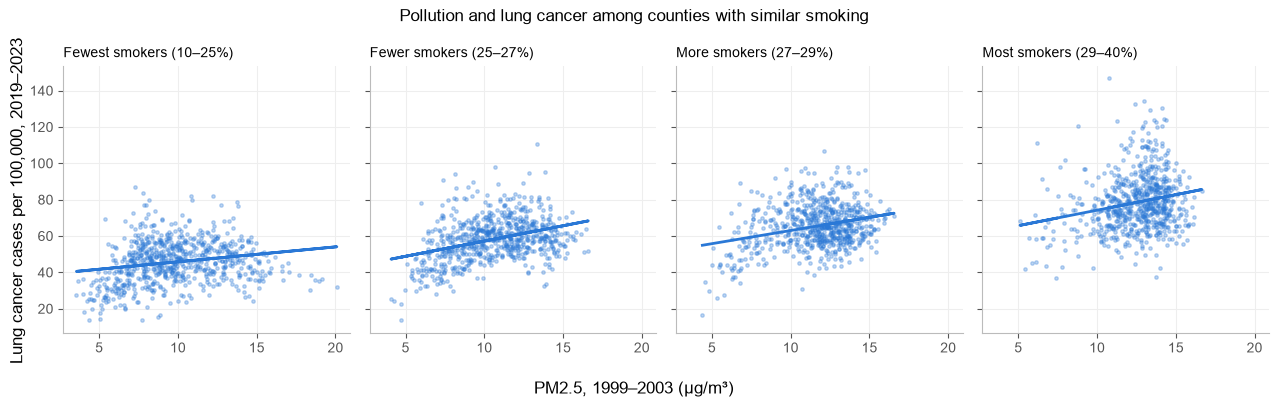

In [14]:
# Split counties into four equal-sized smoking groups
labels = ["Fewest smokers (10–25%)", "Fewer smokers (25–27%)", "More smokers (27–29%)", "Most smokers (29–40%)"]
smoking_groups = pd.qcut(has_rate["smoking"], 4, labels=labels)

# Four charts side by side, all using the same axis scales
fig, axes = plt.subplots(1, 4, figsize=(13, 4), sharex=True, sharey=True)

# For each smoking group: print the numbers, then draw the dots and the line
for i, label in enumerate(labels):
    group = has_rate[smoking_groups == label]
    group_r = group["pm25"].corr(group["cancer_rate"])
    group_slope, group_intercept = np.polyfit(group["pm25"], group["cancer_rate"], 1)
    print(label, "| correlation:", round(group_r, 2), "| slope:", round(group_slope, 1))

    group.plot.scatter(x="pm25", y="cancer_rate", s=6, alpha=0.3, ax=axes[i], xlabel="", ylabel="")
    axes[i].plot(group["pm25"], group_slope * group["pm25"] + group_intercept, color="C0", linewidth=2)
    axes[i].set_title(label, fontsize=10, fontweight="normal")

fig.supxlabel("PM2.5, 1999–2003 (µg/m³)")
fig.supylabel("Lung cancer cases per 100,000, 2019–2023")
fig.suptitle("Pollution and lung cancer among counties with similar smoking")
plt.tight_layout();

# Save the figure
plt.savefig(FIGURES + "Mini_scatterplots_pollution_vs_cancer_by_smoking_groups.png")

Comparing counties with similar smoking cuts the pollution link roughly in half. Instead of 2.8 more cases per 100,000 for each extra µg/m³, it’s between 0.8 and 1.7, and the correlations fall from 0.43 to between 0.20 and 0.36. **But it doesn’t disappear: within every smoking group, more polluted counties still have higher lung cancer rates.** 

## 9. Consider the effect beyond smoking
Using the best-fit line from the smoking scatterplot, we can predict each county's lung cancer rate from its smoking rate alone. The map below shows how far each county's actual rate is above or below that prediction.

Red counties have more lung cancer than smoking would predict, and blue counties have less. These differences don't prove any one cause: they could reflect pollution, but also radon, mining and other industry, people moving, who lives there, or access to screening and care.

Leftovers and pollution: 0.25


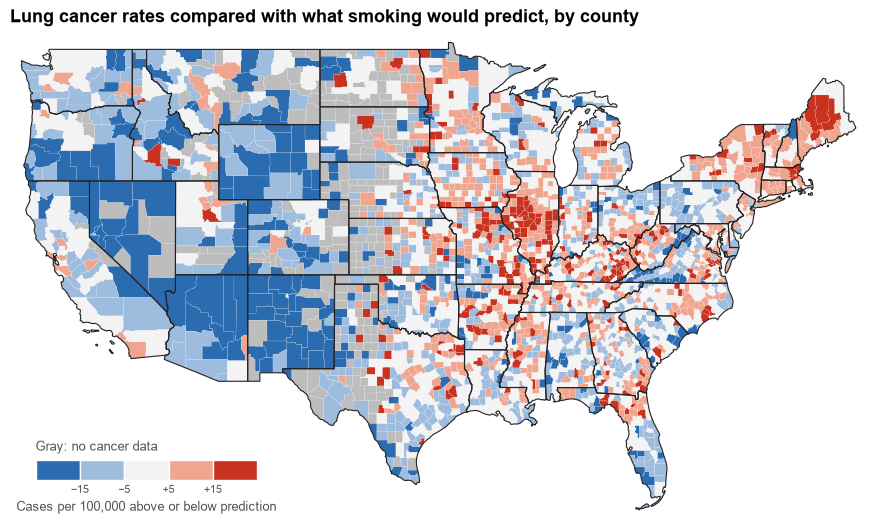

In [15]:
# Leftover = actual cancer rate minus the rate predicted from smoking
# This takes the best-fit line from the smoking scatterplot and subtracts it from the best-fit line from
# the pollution scatterplot. The difference is the "leftover". A positive leftover indicates more cancer
# than smoking predicts, and a lower leftover means less cancer than smoking would predict.
leftover = has_rate["cancer_rate"] - (smoke_slope * has_rate["smoking"] + smoke_intercept)
print("Leftovers and pollution:", round(leftover.corr(has_rate["pm25"]), 2))

# Sort counties into five groups by leftover size, and give each group a color
leftover_group = pd.cut(leftover, [-np.inf, -15, -5, 5, 15, np.inf], labels=False)
leftover_colors = ["#2B6CB0", "#9EBCDE", "#F3F3F3", "#F0A58F", "#C8321F"]
county_color = {fips: leftover_colors[g] for fips, g in zip(has_rate["fips"], leftover_group)}

fig, ax = plt.subplots(figsize=(11, 7))

# Draw counties
for item in shapefile.Reader(RAW + "cb_2020_us_county_20m/cb_2020_us_county_20m.shp").shapeRecords():
    if item.record["STATEFP"] not in skip:
        color = county_color.get(item.record["GEOID"], "#BDBDBD")
        ax.add_patch(PathPatch(outline(item.shape), facecolor=color, edgecolor="white", linewidth=0.1))

# Draw state borders on top
for item in shapefile.Reader(RAW + "cb_2020_us_state_20m/cb_2020_us_state_20m.shp").shapeRecords():
    if item.record["STATEFP"] not in skip:
        ax.add_patch(PathPatch(outline(item.shape), facecolor="none", edgecolor="#222222", linewidth=0.8))

# Frame the lower 48 and hide the axes
ax.set_xlim(-125.5, -66.5)
ax.set_ylim(24, 50)
ax.set_aspect(1.3)
ax.axis("off")

# Draw a color strip as the legend
key = ax.inset_axes([0.03, 0.08, 0.26, 0.04])
for i in range(5):
    key.add_patch(plt.Rectangle((i, 0), 1, 1, facecolor=leftover_colors[i], edgecolor="white"))
key.set_xlim(0, 5)
key.set_ylim(0, 1)
key.set_xticks([1, 2, 3, 4], ["−15", "−5", "+5", "+15"], fontsize=8)
key.set_yticks([])
key.tick_params(length=0)
key.grid(False)
key.spines[:].set_visible(False)
key.set_xlabel("Cases per 100,000 above or below prediction", fontsize=9)
ax.text(0.03, 0.14, "Gray: no cancer data", transform=ax.transAxes, fontsize=9, color="#555555")

ax.set_title("Lung cancer rates compared with what smoking would predict, by county")
plt.savefig(FIGURES + "Choropleth_map_cancer_vs_smoking_prediction.png")

Correlation: 0.25
Share of leftover differences explained: 0.06
Extra cases per 100,000 for each extra 1 µg/m³: 1.1


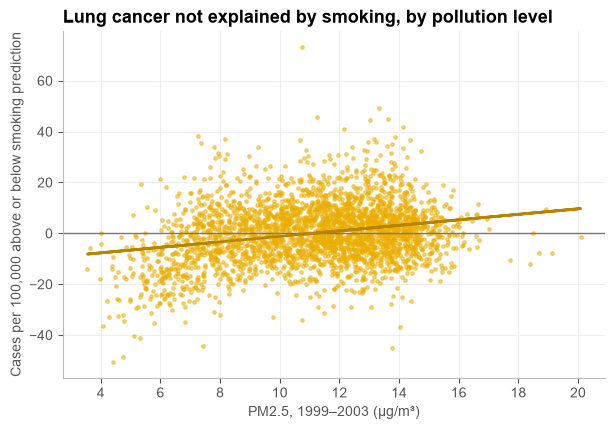

In [16]:
# Add the leftovers (cancer rates with pollution - expected cancer rates with smoking) to the table so I can plot them
has_rate["leftover"] = leftover

# Measure how closely the leftovers track pollution (how closely the counties are clustered near the regression line)
leftover_r = has_rate["leftover"].corr(has_rate["pm25"])
leftover_slope, leftover_intercept = np.polyfit(has_rate["pm25"], has_rate["leftover"], 1)
print("Correlation:", round(leftover_r, 2))
print("Share of leftover differences explained:", round(leftover_r**2, 2))
print("Extra cases per 100,000 for each extra 1 µg/m³:", round(leftover_slope, 1))

# Each dot is a county; dots above the line have more cancer than smoking predicts
ax = has_rate.plot.scatter(x="pm25", y="leftover", s=6, alpha=0.5, color="#EBAE00",
                           xlabel="PM2.5, 1999–2003 (µg/m³)",
                           ylabel="Cases per 100,000 above or below smoking prediction",
                           title="Lung cancer not explained by smoking, by pollution level")
ax.axhline(0, color="#777777", linewidth=1)
ax.plot(has_rate["pm25"], leftover_slope * has_rate["pm25"] + leftover_intercept, color="#B98500", linewidth=2)
ax.set_xticks(range(4, 22, 2))
plt.savefig(FIGURES + "Scatterplot_leftover_vs_pollution.png")

If air pollution matters beyond smoking, counties with more pollution should sit above the line more often. They do, but only slightly. Each additional 1 µg/m³ of PM2.5 is associated with about 1.1 more cases per 100,000 beyond what smoking predicts, and pollution accounts for only about 6% of these remaining differences. The connection is real in the data, but modest, and most of what smoking doesn't explain remains unexplained here.

## 10. What can I conclude about air pollution and lung cancer rates?
Smoking explains a lot, but clearly not everything. Counties with the same smoking rates can have very different lung cancer rates, as the red and blue areas show.

Is air pollution a big part of the reason for this differential? Frankly, it's hard to say for sure. The data suggests it may be, as counties with the cleanest air tend to have less lung cancer than their smoking would predict. But among the rest, more pollution adds little that this data can detect.

So where does that leave the connection between air pollution and lung cancer? It's real in the data, but much smaller than it first appeared. Smoking accounts for most of the pattern, and pollution may account for a modest part of what remains. Other factors, including radon, mining and other industry, people moving, and access to care, could account for the rest. 

I really wanted to blame Pittsburgh's industrial past for my father's death, but apparently it's more complicated than that.

## APPENDIX - FIGURES SANDBOX

In [17]:
# LUNG CANCER RATES
# Put counties into three equal groups on each measure (0 = low, 1 = 1ow/medium, 2 = medium, 3 = medium/high, 4=high)
cancer_level = pd.qcut(has_rate["cancer_rate"], 5, labels=False)

# Rows are pollution (low to high); columns are cancer (low to high)
colors = [["#F3F3F3", "#9EBCDE", "#4A86C8"],
          ["#F5DE85", "#C29C7B", "#905B74"],
          ["#EBAE00", "#E47C18", "#D7301F"]]
county_color = {fips: colors[p][c] for fips, p, c in zip(has_rate["fips"], pollution_level, cancer_level)}

# Turn a shape from the shapefile into an outline (handles islands and holes)
def outline(shape):
    starts = list(shape.parts) + [len(shape.points)]
    return Path.make_compound_path(*[Path(shape.points[a:b]) for a, b in zip(starts, starts[1:])])

fig, ax = plt.subplots(figsize=(11, 7))
skip = ["02", "15", "72"]  # Alaska, Hawaii, Puerto Rico

# Draw counties, then state borders on top
for item in shapefile.Reader(RAW + "cb_2020_us_county_20m/cb_2020_us_county_20m.shp").shapeRecords():
    if item.record["STATEFP"] not in skip:
        color = county_color.get(item.record["GEOID"], "#BDBDBD")
        ax.add_patch(PathPatch(outline(item.shape), facecolor=color, edgecolor="white", linewidth=0.1))

for item in shapefile.Reader(RAW + "cb_2020_us_state_20m/cb_2020_us_state_20m.shp").shapeRecords():
    if item.record["STATEFP"] not in skip:
        ax.add_patch(PathPatch(outline(item.shape), facecolor="none", edgecolor="#222222", linewidth=0.8))

# Frame the lower 48 and hide the axes
ax.set_xlim(-125.5, -66.5)
ax.set_ylim(24, 50)
ax.set_aspect(1.3)
ax.axis("off")

# Draw the 3x3 legend in the corner
key = ax.inset_axes([0.03, 0.06, 0.14, 0.2])
for p in range(3):
    for c in range(3):
        key.add_patch(plt.Rectangle((c, p), 1, 1, facecolor=colors[p][c], edgecolor="white"))
key.set_xlim(0, 3)
key.set_ylim(0, 3)
key.set_aspect("equal")
key.set_xticks([0.5, 1.5, 2.5], ["Low", "Med", "High"], fontsize=8)
key.set_yticks([0.5, 1.5, 2.5], ["Low", "Med", "High"], fontsize=8)
key.tick_params(length=0)
key.grid(False)
key.spines[:].set_visible(False)
key.set_xlabel("More lung cancer →", fontsize=9)
key.set_ylabel("More pollution →", fontsize=9)
ax.text(0.19, 0.06, "Gray: no cancer data", transform=ax.transAxes, fontsize=9, color="#555555")

ax.set_title("Lung cancer (2019–2023) and air pollution (1999–2003) by county")
plt.savefig(FIGURES + "Choropleth_map_pollution_vs_cancer.png")

IndexError: list index out of range